## Settings

In [ ]:
## auto reload modules
%reload_ext autoreload
%autoreload 2

## Dependencies

In [ ]:
## libraries
import sys
import pickle
from pathlib import Path
from IPython.display import display

## path
root = Path.cwd().resolve().parent
fig_path = root / "manuscripts" / "operating" / "figures"
sys.path.insert(0, str(root))

## modules
from src.evaluators.caching import load_notebook_cache
from src.evaluators.operating import (
    format_utilization_table,
    load_utilization_data,
    load_utilization_windows,
    train_utilization_resampling,
    train_utilization_controls,
    train_utilization_windows,
    compile_utilization_benchmark,
    compile_utilization_predictions,
    compile_utilization_controls,
    compile_utilization_superiority,
    stat_utilization_equivalence,
    plot_utilization_frontier,
    plot_utilization_quality,
    plot_utilization_attribution,
    plot_utilization_calibration,
    plot_utilization_controls,
)

## constants
from src.estimators.config import (
    ASYMMETRY_C,
    ASYMMETRY_R,
    ALPHA,
)
from src.evaluators.config import (
    FEAT_X,
    FEAT_Z,
    FEAT_XU,
    FEAT_ZU,
    TARGET,
)
from src.evaluators.operating import (
    GLM_ESTIMATORS,
    SCT_MODALITIES,
    RESAMPLING_REGIMES,
)

## Initialization

In [ ]:
## reproducibility
N_DECIMALS = 2
N_REPEATS = 30
N_BOOT = 10000
N_BOOT_CI = 1000
RANDOM_STATE = 42
FORCE_RECOMPUTE = False
STATISTICS_VERSION = "full-precision-benchmark-v3"

## load data
data = load_utilization_data()
data_windows = load_utilization_windows(data = data)

## view data and model surface
n_obs, n_feat = data.shape
print(f"Original Data: {n_feat} features, {n_obs} observations")
print(f"Learned Models: {len(GLM_ESTIMATORS)} families, {len(SCT_MODALITIES)} estimation regimes")

## cache setup
cache_path = root / "notebooks" / "cache" / "operate_results.pkl"
cache_metadata = {
    "analysis": "six-configuration-point-predictions-v3",
    "n_obs": n_obs,
    "n_repeats": N_REPEATS,
    "n_boot": N_BOOT,
    "n_boot_ci": N_BOOT_CI,
    "random_state": RANDOM_STATE,
    "target": TARGET,
    "feat_x": list(FEAT_X),
    "feat_z": list(FEAT_Z),
    "feat_xu": list(FEAT_XU),
    "feat_zu": list(FEAT_ZU),
    "glm_families": list(GLM_ESTIMATORS),
    "sct_modes": list(SCT_MODALITIES),
    "resampling_regimes": list(RESAMPLING_REGIMES),
    "window_fractions": list(data_windows),
    "quantile_c": ASYMMETRY_C,
    "quantile_r": ASYMMETRY_R,
    "alpha": ALPHA,
    "data": data.to_json(double_precision = 15),
    "window_data": {fraction: frame.to_json(double_precision = 15) for fraction, frame in data_windows.items()},
    "rho_rescaled": True,
}
cache_keys = ("results_resampling", "predicts_controls", "predicts_windows", "results_tables")
cache_payload = load_notebook_cache(
    cache_path = cache_path,
    metadata = cache_metadata,
    required_keys = cache_keys,
    force_recompute = FORCE_RECOMPUTE,
)
if cache_payload is not None:
    globals().update({key: cache_payload[key] for key in cache_keys})

Original Data: 40 features, 25 observations
Learned Models: 3 families, 2 estimation regimes
Loaded results from /Users/nickkunz/Documents/Nick’s MacBook Pro/Python/network-capacity/notebooks/cache/operate_results.pkl


## Training

In [ ]:
## nested cross-validation and repeated random splits
if cache_payload is None:
    results_resampling = train_utilization_resampling(
        data = data,
        n_repeats = N_REPEATS,
        random_state = RANDOM_STATE,
    )

In [ ]:
## component ablations and temporally separated evaluation
if cache_payload is None:
    predicts_controls = train_utilization_controls(
        data = data,
        resampling = results_resampling,
        n_repeats = N_REPEATS,
        random_state = RANDOM_STATE,
    )
    predicts_windows = train_utilization_windows(
        frames = data_windows,
        random_state = RANDOM_STATE,
    )

## Post-Processing

In [ ]:
## compile descriptive and paired statistical results
if cache_payload is None:
    results_tables = compile_utilization_predictions(
        data = data,
        resampling = results_resampling,
    )
    results_tables.update(stat_utilization_equivalence(
        data = data,
        resampling = results_resampling,
        decimals = N_DECIMALS,
    ))
    results_tables.update(compile_utilization_controls(
        data = data,
        controls = predicts_controls,
        frames = data_windows,
        windows = predicts_windows,
        n_boot = N_BOOT,
        n_boot_ci = N_BOOT_CI,
        random_state = RANDOM_STATE,
    ))

    ## persist canonical utilization results
    cache_path.parent.mkdir(parents = True, exist_ok = True)
    cache_payload = {
        "metadata": cache_metadata,
        "results_resampling": results_resampling,
        "predicts_controls": predicts_controls,
        "predicts_windows": predicts_windows,
        "results_tables": results_tables,
    }
    cache_path.write_bytes(pickle.dumps(obj = cache_payload))
    print(f"Cached utilization results -> {cache_path}")

In [ ]:
## refresh benchmark scores and inference
statistics_metadata = {"version": STATISTICS_VERSION}
if cache_payload.get("statistics_metadata") != statistics_metadata or not all(
    key in results_tables for key in ("superiority", "ablation_tests", "temporal_tests")
):
    results_tables["benchmark"] = compile_utilization_benchmark(
        df_data = data,
        predictions = results_resampling["predictions"][RESAMPLING_REGIMES[0]],
    )
    results_tables.update(compile_utilization_superiority(
        data = data,
        controls = predicts_controls,
        frames = data_windows,
        windows = predicts_windows,
        tables = results_tables,
    ))
    cache_payload["results_tables"] = results_tables
    cache_payload["statistics_metadata"] = statistics_metadata
    cache_path.write_bytes(pickle.dumps(obj = cache_payload))
    print("Updated full-precision benchmark and superiority statistics without refitting models.")

## Multiplicative Error
Poisson, Poisson-Tweedie, and Negative Binomial estimation are compared under SCT Frontier Exclusion and SCT Frontier Anchor across 25 systems in 5 domains, with Domain LOGO-CV as the primary evaluation. Held-out log-rate estimates are first compared with observed log-rates and summarized by multiplicative error on the original rate scale, using Negative Binomial estimation under Domain LOGO-CV. Table 3 retains point-prediction and multiplicative-accuracy metrics for every family, estimation regime, and resampling regime.

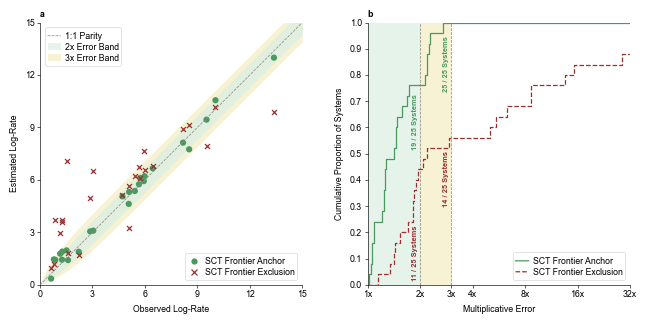

In [ ]:
## out-of-sample agreement and multiplicative accuracy
figure = plot_utilization_calibration(
    tables = results_tables, index = 1, output_dir = fig_path
)
display(figure)

_**Figure 1. Estimation-observation agreement and multiplicative error.** Out-of-fold Negative Binomial estimation under domain-level LOGO-CV across 25 systems. **a**. Estimated versus observed log-rates using the SCT frontier anchor (green circles) and SCT frontier exclusion (red crosses) relative to parity (diagonal gray dashed line). Green and yellow shading mark twofold and threefold multiplicative error, defined on the original rate scale. **b**. Empirical cumulative distributions of multiplicative error using the frontier anchor (green solid trace) and frontier exclusion (red dashed trace). Vertical dashed lines and shading mark twofold (green) and threefold (yellow) error, and annotations report the number of systems within each threshold._

## Prediction Quality
Prediction quality is compared across all three GLM families and both estimation regimes. Table 2 reports MAE, RMSE, consensus index, and geometric mean multiplicative error under Domain LOGO-CV, and Table 3 reports them across all four resampling regimes.

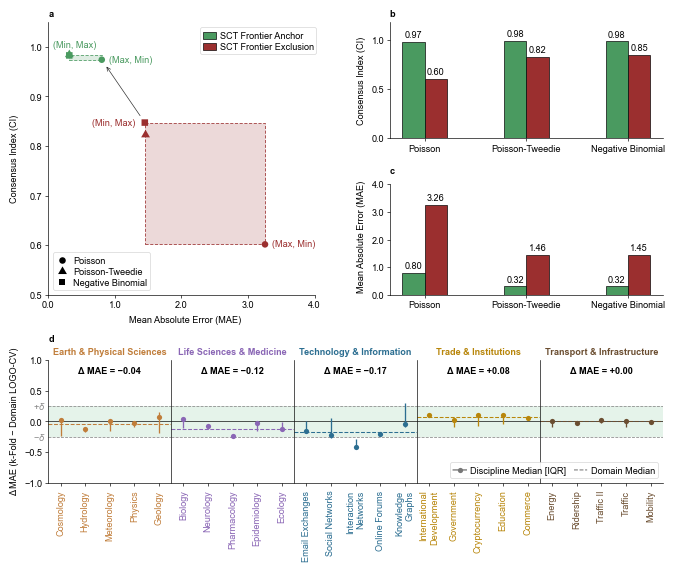

In [ ]:
## prediction quality and resampling comparison
figure = plot_utilization_quality(
    tables = results_tables, data = data, resampling = results_resampling,
    index = 2, output_dir = fig_path,
)
display(figure)

_**Figure 2. Prediction quality of frontier-anchored operating rates.** 3 GLM families estimate operating rates for 25 systems in 5 broad domains using the SCT frontier anchor (green) and SCT frontier exclusion (red). **a**. Estimation-observation consensus (CI) by Mean Absolute Error (MAE) under domain-level LOGO-CV. Marker shapes identify Poisson (circle), Poisson-Tweedie (triangle), and Negative Binomial (square) estimation. Shaded rectangles span coordinate-wise ranges across families for each estimation regime (dashed outlines) with labeled (Min, Max) and (Max, Min) corners, and the arrow connects Negative Binomial estimation from frontier exclusion to frontier anchor. **b**. CI by GLM family under domain-level LOGO-CV. **c**. MAE by GLM family under domain-level LOGO-CV. **d**. Paired differences in absolute log-rate error between repeated $k$-Fold-CV and domain-level LOGO-CV using the frontier anchor. Markers with vertical intervals exhibit discipline medians and interquartile ranges across 3 families and 2 random-split regimes (domain-color intervals), dashed horizontal lines exhibit domain medians (domain-color dashed lines), and the horizontal shading is the equivalence margin ($\pm\delta_{\mathrm{MAE}}$, green shaded band). Annotations report (**b**) family CI, (**c**) family MAE, and (**d**) domain $\Delta\mathrm{MAE}$._

In [ ]:
display(format_utilization_table(
    frame = results_tables["benchmark"],
    title = 'Table 2. Prediction quality under domain-level LOGO-CV.',
    columns = ['Estimator', 'Estimation Regime', 'MAE', 'RMSE', 'CI', 'GMME'],
    groups = ['Estimator', 'Estimation Regime'],
    note = (
        "Out-of-fold estimates for 25 systems in 5 broad domains, with each of 5 folds withholding 1 domain. "
        "Poisson (with interval exposure), Poisson-Tweedie (power 1.75), and Negative Binomial families are fitted by L2-penalized likelihood or deviance, with penalties selected from {1, 2, 5, 10} by inner 4-fold CV. "
        "SCT Frontier Anchor adds the out-of-fold frontier minus the EVT statistic as a fixed offset and caps estimates at the frontier. "
        "MAE and RMSE are computed on log-rates ln(1 + r). "
        "GMME is the geometric mean of max(r̂ / r, r / r̂), where 1 indicates exact agreement. "
        "CI is the consensus index, the geometric mean of rescaled Spearman ρ, rank-biased overlap (p = 0.9), and distance correlation on [0, 1]. "
        "Lower MAE, RMSE, and GMME and higher CI indicate better performance."
    ),
    decimals = N_DECIMALS,
))

## Resampling Equivalence
Table S1 pairs three families across five domains, averaging metrics from 30 random-split repeats before pairing with a fixed inner four-fold seed. Each equivalence margin is the IQR of the three domain-averaged model scores under Domain LOGO-CV, rounded upward to two decimals. Paired Wilcoxon TOST p-values receive Holm adjustment across the three regime comparisons separately for each metric.

In [ ]:
display(format_utilization_table(
    frame = results_tables["equivalence"],
    title = 'Table S1. Equivalence of resampling regimes to domain-level LOGO-CV.',
    columns = ['Metric', 'Comparison', 'Median Δ', 'Rank-biserial r', 'Holm-adj. p', 'Eq.'],
    groups = ['Metric', 'Comparison'],
    note = (
        "Paired Wilcoxon two one-sided tests (TOST) comparing each resampling regime with domain-level LOGO-CV for SCT Frontier Anchor estimation. "
        "Each comparison uses 15 paired cells (3 GLM families × 5 domains), with metrics scored within each domain. "
        "Random-split metrics are averaged over 30 outer seeds (42–71) before pairing, with the inner 4-fold seed fixed at 42, while LOGO regimes are deterministic. "
        "Median Δ is the median paired difference (comparison regime − domain-level LOGO-CV). "
        "Rank-biserial r uses nonzero differences with average ranks, and positive values indicate larger metric values under the comparison regime. "
        "TOST applies one-sided signed-rank tests to Δ − δ and Δ + δ, and p is the larger of the two. "
        "Differences below 10⁻¹⁰ in magnitude were zeroed, and tests used SciPy 1.16.3 defaults (zero_method='wilcox', method='auto', correction=False). "
        "Margins are IQRs across the 3 family means under domain-level LOGO-CV, rounded up to 2 decimals: "
        + ', '.join(
            f'δ_{metric} = {delta:.{N_DECIMALS}f}'
            for metric, delta in results_tables["equivalence"].groupby(by = 'Metric', sort = False)['delta'].first().items()
        )
        + '. Holm adjustment covers the 3 regime comparisons separately for each metric, and Eq. requires adjusted p < 0.05. '
        'Shared training systems and domains make inference conditional on this dependent panel.'
    ),
    decimals = N_DECIMALS,
))

## Capacity Frontier Decomposition
The SCT capacity frontier is decomposed into the observed operating rate, the EVT statistic, and the remaining utilization slack for each of the 25 systems. The tables below report the frontier components and the held-out log-rate estimates. Corpus characteristics and complete records appear in Complete Results.

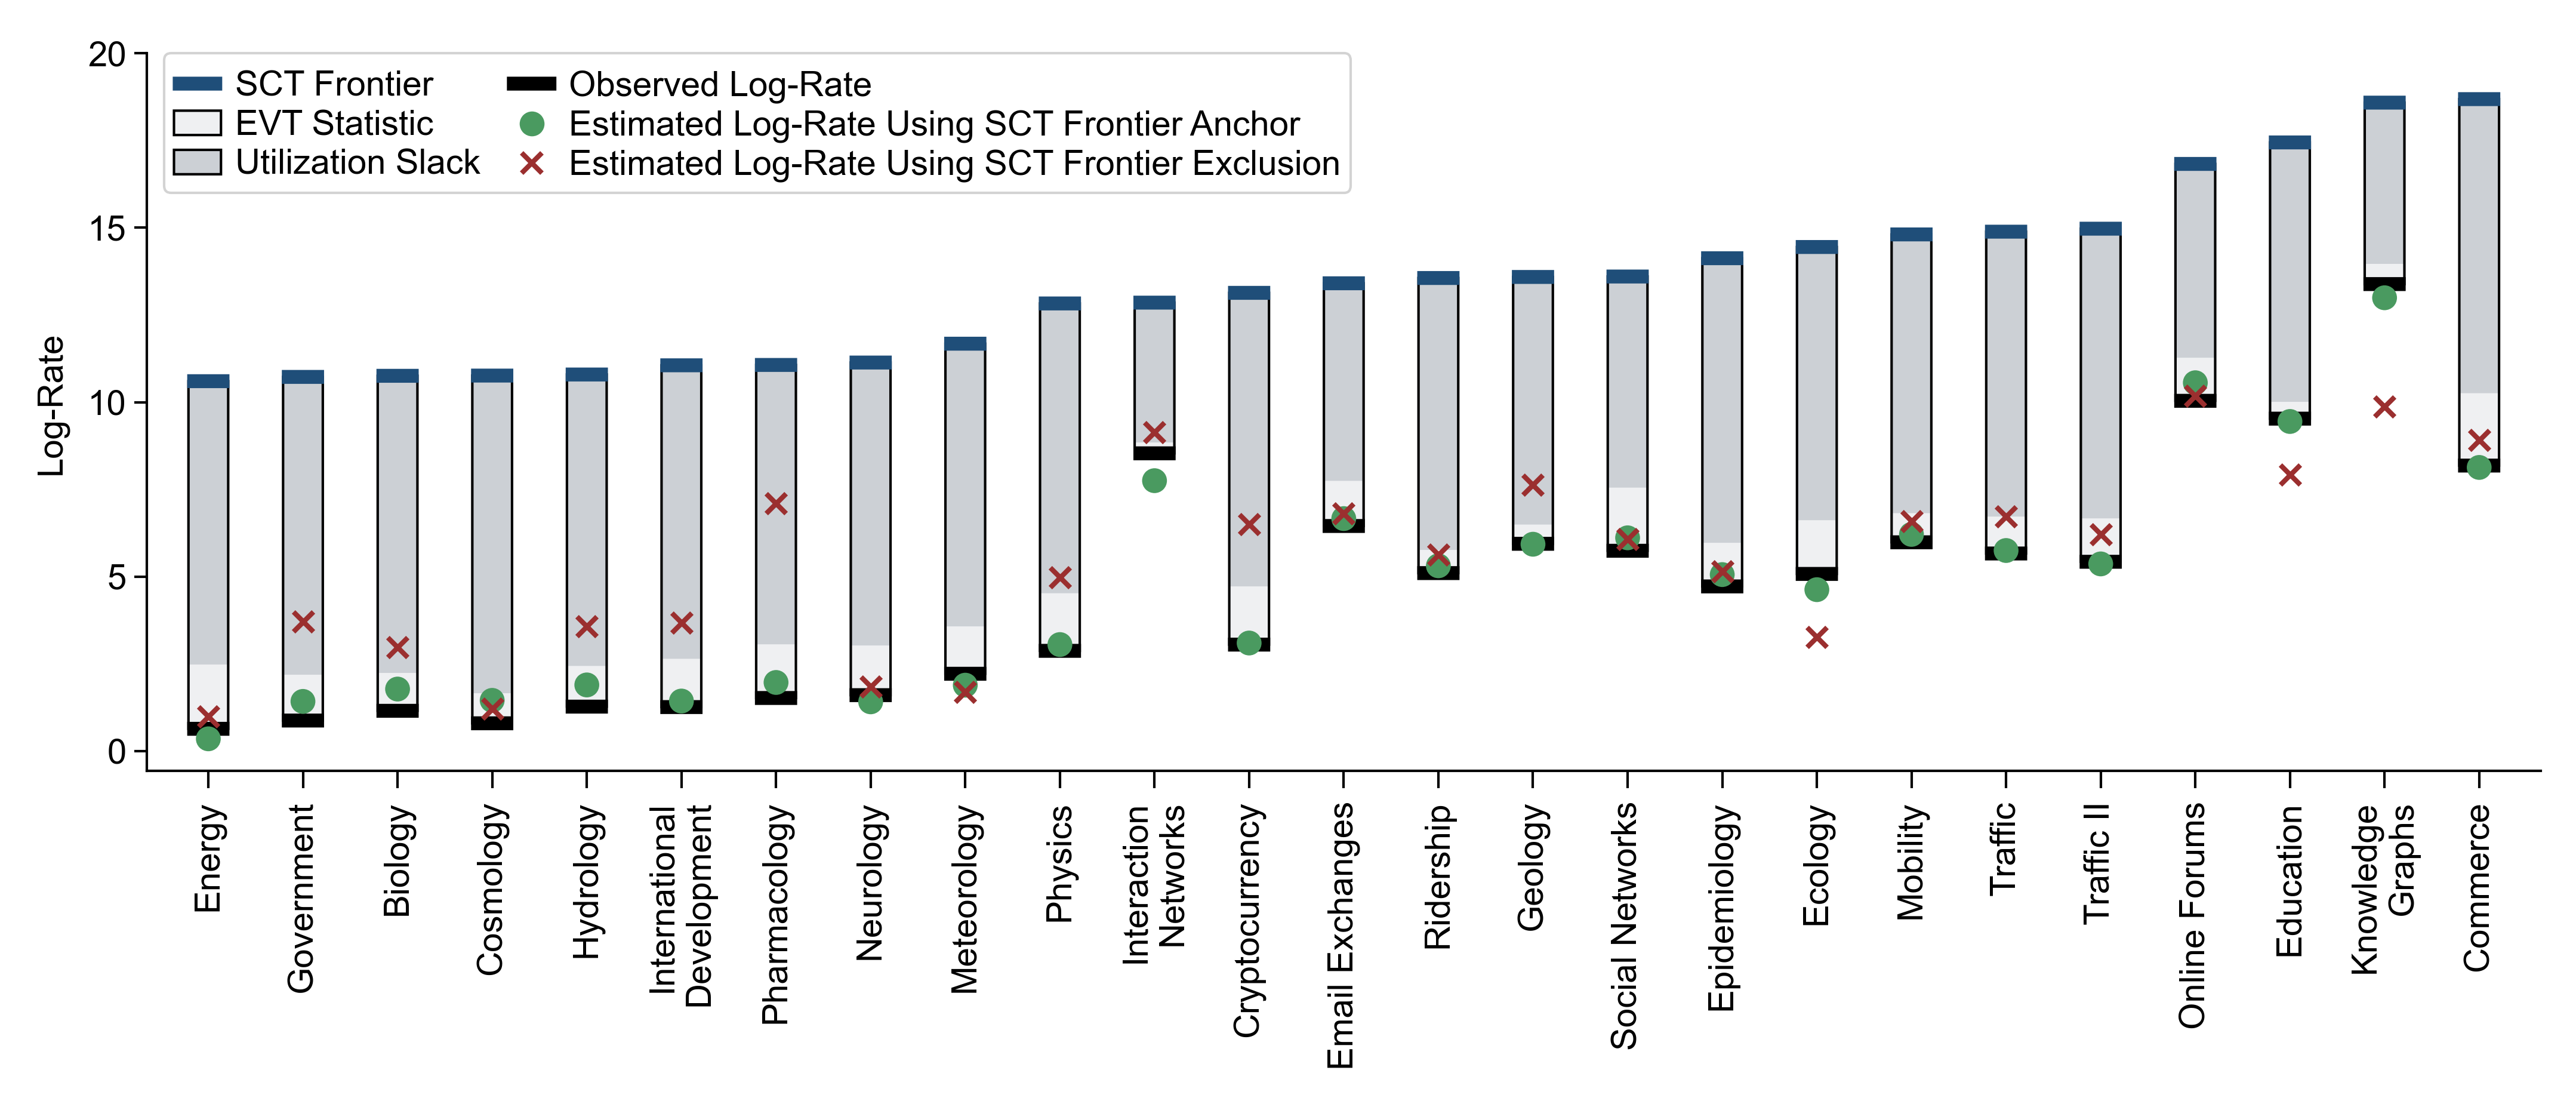

In [ ]:
## capacity frontier decomposition
figure = plot_utilization_frontier(
    data = data, resampling = results_resampling, index = 3, output_dir = fig_path
)
display(figure)

_**Figure 3. Decomposition of the capacity frontier.** Out-of-fold Negative Binomial estimation under domain-level LOGO-CV across 25 systems, ordered by the estimated capacity frontier. Stacked bars exhibit the observed mean log-rate (black segment, bottom), the EVT statistic slack (light gray segment), the utilization slack (dark gray segment), and the SCT frontier (blue segment, top). Markers exhibit estimated log-rates using the SCT frontier anchor (green circles) and SCT frontier exclusion (red crosses). The mean rate is the total count divided by the number of observed intervals, and EVT segments are capped at the frontier where descriptive slack is negative. The SCT frontier is estimated from all 21 graph invariants and 7 process signatures, while the operating-rate estimators use 3 graph invariants and 3 process signatures, excluding the Fano factor._

In [ ]:
display(format_utilization_table(
    frame = results_tables["targets"].query(expr = '`Resampling Regime` == @RESAMPLING_REGIMES[0]'),
    title = 'Frontier decomposition by system.',
    columns = ['System', 'Observed_LogRate', 'Frontier', 'EVT', 'Slack'],
    groups = ['System'],
    note = (
        "Out-of-fold quantities for 25 systems under domain-level LOGO-CV, with each of 5 folds withholding 1 broad domain. "
        "The SCT frontier is the two-stage linear quantile estimate f_C(x′; τ = 0.99) + f_R(z′; τ = 0.50), with f_R centered on its training mean, fitted to log-maxima ln(1 + r_max) from 21 graph invariants and 7 process signatures. "
        "The observed log-rate is ln(1 + r_mean), where r_mean is the total count divided by the number of observed intervals. "
        "The EVT statistic is ln(1 + CV √(2 ln L)) for coefficient of variation CV and L intervals. "
        "Slack is the frontier minus the EVT statistic and observed log-rate. "
        "Values are descriptive and independent of GLM family."
    ),
    decimals = N_DECIMALS,
))

,Observed_LogRate,Frontier,EVT,Slack
System,,,,
amazon,8.18,18.69,2.07,8.43
auger,2.87,12.83,1.65,8.31
bitcoin,3.05,13.13,1.66,8.42
celegans,1.15,10.76,1.08,8.52
chickenpox,4.72,14.13,1.25,8.16
college,5.74,13.60,1.81,6.05
crop,5.08,14.45,1.54,7.84
email,6.45,13.41,1.29,5.67
epilepsy,1.60,11.14,1.42,8.11


In [ ]:
display(format_utilization_table(
    frame = results_tables["systems"].pivot(index = ["System", "Observed_LogRate"], columns = "Configuration", values = "Predicted_LogRate").reset_index(),
    title = 'Table 4. Observed and estimated log-rates by system.',
    groups = ['System', 'Observed_LogRate'],
    note = (
        "Held-out estimates for 25 systems from Negative Binomial estimation under domain-level LOGO-CV, where each system is estimated by the fold that withholds its domain. "
        "Estimates are ln(1 + r̂) for predicted mean rate r̂, and observed values are ln(1 + r_mean). "
        "SCT Frontier Exclusion fits 3 graph invariants and 3 process signatures without an offset. "
        "SCT Frontier Anchor adds the out-of-fold frontier minus the EVT statistic as a fixed log-rate offset and caps estimates at the frontier. "
        "Features are signed-log1p transformed and standardized within each training fold, and L2 penalties are selected from {1, 2, 5, 10} by inner 4-fold CV."
    ),
    decimals = N_DECIMALS,
))

,Configuration,SCT Frontier Anchor,SCT Frontier Exclusion
System,Observed_LogRate,,
amazon,8.181954,8.13,8.92
auger,2.871350,3.05,4.97
bitcoin,3.050213,3.10,6.50
celegans,1.152680,1.78,2.98
chickenpox,4.718316,5.06,5.14
college,5.739876,6.11,6.08
crop,5.076046,4.63,3.27
email,6.450176,6.66,6.81
epilepsy,1.601406,1.41,1.84


## Target Contraction
Target dispersion is compared before and after frontier anchoring, alongside the fitted coefficients of the downstream operating-rate estimators. Both comparisons use Negative Binomial estimation under Domain LOGO-CV, the primary evaluation setting. Tables S5 and S6 report target contraction and coefficient summaries across all four resampling regimes and three GLM families.

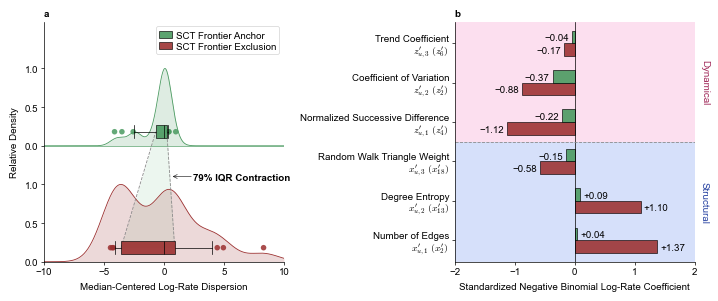

In [ ]:
## target dispersion and utilization feature coefficients
figure = plot_utilization_attribution(
    tables = results_tables, index = 4, output_dir = fig_path
)
display(figure)

_**Figure 4. Target dispersion and feature attribution.** Out-of-fold Negative Binomial estimation under domain-level LOGO-CV across 25 systems. **a**. Median-centered dispersion of the observed log-rate targeted under SCT frontier exclusion (red, bottom) and the utilization slack targeted under SCT frontier anchor (green, top), where slack is the held-out SCT frontier minus the EVT statistic and observed log-rate. Shaded curves exhibit Gaussian kernel densities (bandwidth factor 0.38) scaled independently to unit peak. Boxes exhibit medians and IQRs, whiskers span the 10th to 90th percentiles, and points exhibit systems beyond the whiskers. Dashed gray lines connect corresponding quartiles, and the annotation reports IQR contraction. **b**. Standardized log-rate coefficients for 3 process signatures (Dynamical, pink region) and 3 graph invariants (Structural, blue region) under frontier anchor (green bars) and frontier exclusion (red bars). Coefficients are equally weighted outer-fold means of the nested-CV fits and describe fitted associations._

## Target Contraction Across Regimes
Table S5 reports IQR and population-variance contraction of descriptive slack relative to observed log-rate. Each regime contributes one out-of-fold frontier, so the calculation is independent of GLM family. Contraction is one minus the ratio of slack dispersion to observed dispersion, and negative values indicate increased dispersion.

In [ ]:
display(format_utilization_table(
    frame = results_tables["contraction"],
    title = 'Table S5. Target contraction across resampling regimes.',
    columns = ['Resampling Regime', 'Observed IQR', 'Slack IQR', 'IQR Contraction (%)', 'Observed Variance', 'Slack Variance', 'Variance Contraction (%)'],
    groups = ['Resampling Regime'],
    note = (
        "Dispersion of the observed log-rate ln(1 + r_mean) and of utilization slack across 25 systems. "
        "Slack is the out-of-fold SCT frontier minus the EVT statistic and observed log-rate, with one frontier estimate per system from each regime, and random-split regimes use the seed-42 split. "
        "The calculation precedes operating-rate estimation and is independent of GLM family, so observed columns are identical across regimes. "
        "Variances are population variances. "
        "Contraction (%) = 100 × (1 − slack dispersion / observed dispersion), and negative values would indicate increased dispersion."
    ),
    decimals = N_DECIMALS,
))

,Observed IQR,Slack IQR,IQR Contraction (%),Observed Variance,Slack Variance,Variance Contraction (%)
Resampling Regime,,,,,,
10-Fold-CV,4.46,0.69,84.51,11.11,1.78,83.97
5-Fold-CV,4.46,1.10,75.33,11.11,2.05,81.50
Discipline LOGO-CV,4.46,0.39,91.20,11.11,1.07,90.36
Domain LOGO-CV,4.46,0.92,79.40,11.11,1.67,84.96


## Coefficient Magnitudes Across Regimes
Table S6 covers all 72 feature-family-regime combinations from the same nested-CV fits that produce the held-out estimates. Shrinkage compares mean absolute standardized coefficients across outer folds, and negative values indicate increased magnitude. Fold standard deviations describe variability across fits rather than inferential uncertainty.

In [ ]:
display(format_utilization_table(
    frame = results_tables["coefficients"],
    title = 'Table S6. Standardized coefficients across resampling regimes and estimators.',
    groups = ['Resampling Regime', 'Estimator', 'Feature'],
    note = (
        "Coefficients for 3 graph invariants and 3 process signatures from every outer fold of the nested-CV fits: 5 folds for domain-level LOGO-CV and 5-Fold-CV, 25 for discipline-level LOGO-CV, and 10 for 10-Fold-CV. "
        "Features are signed-log1p transformed and standardized within each outer training set, so coefficients are changes in log mean rate per training standard deviation. "
        "Means and fold SDs (ddof = 1) summarize coefficients across folds and describe variation across fits rather than inferential uncertainty. "
        "Magnitude reduction (%) = 100 × (1 − mean |anchor coefficient| / mean |exclusion coefficient|), and negative values indicate larger magnitudes under the anchor."
    ),
    decimals = N_DECIMALS,
))

## Component Ablation and Temporal Separation
Seven alternatives are compared with the SCT Frontier Anchor, and temporal checks separate the samples that supply model inputs from those that supply target operating rates. All four resampling regimes and three families are evaluated. Intervals use 10,000 paired system bootstrap samples, with the first 1,000 for CI, and fitted models remain fixed.

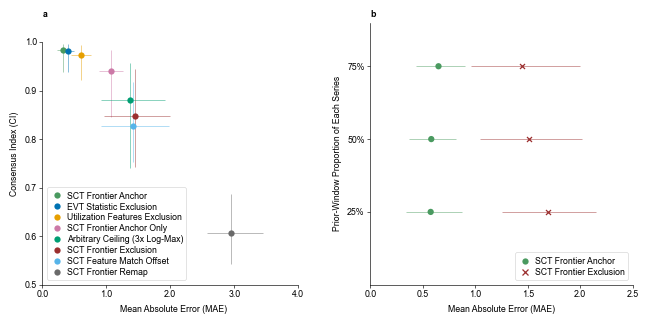

In [ ]:
## ablation and temporal-window evaluation
figure = plot_utilization_controls(
    tables = results_tables, index = 5, output_dir = fig_path
)
display(figure)

_**Figure 5. Component ablation and temporal separation.** Negative Binomial estimation under domain-level LOGO-CV across 25 systems. **a**. Estimation-observation consensus (CI) by Mean Absolute Error (MAE) for the SCT frontier anchor and 7 alternatives: EVT statistic exclusion, utilization features exclusion, SCT frontier anchor only, an arbitrary ceiling at 3 times the maximum training log-maximum within each outer and inner fold, SCT frontier exclusion, a feature-matched offset fit at the median from the same 28 SCT inputs with EVT as a downstream feature and no cap, and SCT frontier remap averaged over 30 derangements. **b**. MAE when process signatures, EVT statistics, and frontier training maxima are computed from the first 25%, 50%, or 75% of each chronologically ordered series and target operating rates from the remaining intervals, using the frontier anchor (green circles) and frontier exclusion (red crosses). Graph invariants span both windows. In **a** and **b**, markers exhibit point estimates and lines exhibit 95% paired system-bootstrap percentile intervals with fitted models held fixed._

## Superiority Tests
One-sided Wilcoxon tests evaluate superiority above zero for MAE, RMSE, CI, and GMME over 15 paired model-family-by-domain values, with positive differences favoring the anchor. Superiority requires a Holm-adjusted p-value below 0.05 and a positive median difference. Holm correction is separate for each metric, covering 7 primary or 28 complete ablation contrasts and 1 primary or 12 complete temporal contrasts.

In [ ]:
display(format_utilization_table(
    frame = results_tables["ablation_tests"].query(expr = '`Resampling Regime` == @RESAMPLING_REGIMES[0]'),
    title = 'Table 5. Superiority of SCT Frontier Anchor over component ablations.',
    columns = ['Metric', 'Comparator', 'Median Δ', 'Rank-biserial r', 'Holm-adj. p', 'Sp.'],
    groups = ['Metric', 'Comparator'],
    note = (
        "One-sided Wilcoxon signed-rank tests of SCT Frontier Anchor superiority over 7 component ablations under domain-level LOGO-CV. "
        "Each test uses 15 paired cells (3 GLM families × 5 domains), with metrics scored within each domain from fixed out-of-fold predictions. "
        "SCT Frontier Remap cells average metrics over 30 frontier derangements after scoring. "
        "Differences are oriented so that positive values favor the anchor: comparator − anchor for MAE, RMSE, and GMME, and anchor − comparator for CI. "
        "Median Δ is the median paired difference, and rank-biserial r uses nonzero differences with average ranks. "
        "Differences below 10⁻¹⁰ in magnitude were zeroed, and tests used SciPy 1.16.3 with alternative='greater' and default settings. "
        "Holm adjustment covers the 7 comparators separately for each metric, and Sp. requires adjusted p < 0.05 and a positive Median Δ. "
        "Complete-family corrections across all 4 resampling regimes appear in Table S13. "
        "Shared training systems and domains make inference conditional on this dependent panel."
    ),
    decimals = N_DECIMALS,
))

In [ ]:
display(format_utilization_table(
    frame = results_tables["temporal_tests"].query(expr = '`Resampling Regime` == @RESAMPLING_REGIMES[0] and `Prior-Window Share` == "50%"'),
    title = 'Table S3. Superiority of SCT Frontier Anchor under temporal separation.',
    columns = ['Metric', 'Median Δ', 'Rank-biserial r', 'Holm-adj. p', 'Sp.'],
    groups = ['Metric'],
    note = (
        "One-sided Wilcoxon signed-rank tests of SCT Frontier Anchor superiority over SCT Frontier Exclusion at the primary temporal setting, the 50% prior window under domain-level LOGO-CV. "
        "Process signatures, EVT statistics, and frontier log-maxima use the first half of each chronologically ordered series, target mean rates use the remaining intervals, and graph invariants are static. "
        "Each test uses 15 paired cells (3 GLM families × 5 domains). "
        "Differences are oriented so that positive values favor the anchor: exclusion − anchor for MAE, RMSE, and GMME, and anchor − exclusion for CI. "
        "Rank-biserial r uses nonzero differences with average ranks, and differences below 10⁻¹⁰ in magnitude were zeroed. "
        "With 1 contrast per metric, Holm adjustment leaves p unchanged, and Sp. requires adjusted p < 0.05 and a positive Median Δ. "
        "Remaining windows and regimes appear in Tables S2, S4, and S13. "
        "Shared training systems and domains make inference conditional on this dependent panel."
    ),
    decimals = N_DECIMALS,
))

,Median Δ,Rank-biserial r,Holm-adj. p,Sig.,Sp.
Metric,,,,,
CI,0.11,0.68,0.009,**,Yes
MAE,1.49,0.95,<0.001,***,Yes
RMSE,1.56,0.95,<0.001,***,Yes
GMME,7.89,0.95,<0.001,***,Yes


## Complete Results
Complete tables retain all evaluated settings and system-level records, following the order of the analyses above. Each table is grouped by its evaluation setting. CI denotes consensus index, and interval columns explicitly identify their confidence level.

## Corpus Characteristics
Table 1 describes each of the 25 systems by domain, number of observed intervals, and total event count. It reports the mean and maximum operating rates on the original and log scales, with utilization given as the mean rate as a percentage of the maximum. These records supply the targets used throughout the analyses above.

In [ ]:
display(format_utilization_table(
    frame = results_tables["corpus"].rename(columns = {"name":"System","domain":"Domain","L":"Intervals","M":"Total Count","r_mean":"Mean Rate","r_max":"Maximum Rate","y_mean":"Mean Log-Rate","y_max":"Maximum Log-Rate","Util_%":"Utilization (%)"}),
    title = 'Table 1. Corpus characteristics.',
    groups = ['Domain', 'System'],
    note = (
        "Each row is 1 of 25 systems, grouped into 5 broad domains with 5 systems each. "
        "Intervals (L) is the number of observed intervals in each series, and total count (M) sums events across them. "
        "Mean rate r_mean = M / L, and maximum rate r_max is the largest observed interval rate. "
        "Log-rates are ln(1 + r), so mean log-rate is the operating-rate target and maximum log-rate is the frontier target. "
        "Utilization (%) = 100 × r_mean / r_max. "
        "Series definitions, observation windows, and sources follow the companion corpus records."
    ),
    decimals = N_DECIMALS,
))

## Prediction and Resampling
Table 3 reports MAE, RMSE, consensus index, and geometric mean multiplicative error for every resampling regime, GLM family, and estimation regime. These complete metrics extend the primary benchmark in Table 2 and support the resampling equivalence tests in Table S1.

In [ ]:
display(format_utilization_table(
    frame = results_tables["predictive"],
    title = 'Table 3. Predictive metrics across all settings.',
    groups = ['Resampling Regime', 'Estimator', 'Configuration'],
    note = (
        "Out-of-fold metrics for every combination of 4 resampling regimes, 3 GLM families, and 2 estimation regimes across 25 systems. "
        "Domain-level LOGO-CV withholds 1 of 5 broad domains per fold, discipline-level LOGO-CV withholds 1 of 25 disciplines, and k-Fold-CV uses shuffled splits with seed 42, while repeated random splits enter only Table S1. "
        "Penalties are selected by inner 4-fold CV within each training fold. "
        "MAE and RMSE use log-rates ln(1 + r), GMME is the geometric mean multiplicative error on the rate scale, and CI is the consensus index. "
        "Within 2x and 3x report the percentage of systems whose estimated rate lies within a factor of 2 or 3 of the observed rate."
    ),
    decimals = N_DECIMALS,
))

## Ablations and Temporal Evaluation
Table 6 and Tables S2 and S4 report complete component-ablation and temporal estimates with paired-bootstrap 95% intervals. A carry-forward baseline predicts later activity from the earlier observed mean rate at the 50% split. Table S9 compares anchored temporal predictions with the frontier cap enabled and disabled.

In [ ]:
display(format_utilization_table(
    frame = results_tables["ablation_complete"],
    title = 'Table 6. Component-ablation estimates across all settings.',
    groups = ['Resampling Regime', 'Estimator', 'Configuration'],
    note = (
        "Point estimates and paired system-bootstrap intervals for SCT Frontier Anchor and 7 ablations across 4 resampling regimes and 3 GLM families. "
        "Ablations remove the EVT offset, replace utilization features with an intercept, or both; remove the frontier offset; substitute a constant ceiling at 3 × the maximum training log-maximum within each outer and inner fold; fit an offset at the median of mean log-rates from the same 28 SCT inputs with EVT as a feature and no cap; or remap the out-of-fold frontier across 30 derangements. "
        "Intervals are 2.5th–97.5th percentiles over 10,000 resamples of the 25 systems (seed 42), shared across configurations, with fitted models held fixed, and CI intervals use the first 1,000. "
        "Remap metrics are averaged over derangements within each resample."
    ),
    decimals = N_DECIMALS,
))

In [ ]:
display(format_utilization_table(
    frame = results_tables["temporal_complete"],
    title = 'Tables S2 and S4. Temporal estimates across all settings.',
    groups = ['Prior-Window Share', 'Resampling Regime', 'Estimator', 'Configuration'],
    note = (
        "Point estimates and paired system-bootstrap intervals for SCT Frontier Anchor and SCT Frontier Exclusion across 3 prior-window shares, 4 resampling regimes, and 3 GLM families. "
        "For each share, the first ⌊share × L⌋ chronologically ordered intervals supply process signatures, EVT statistics, and frontier log-maxima, and the remaining intervals supply target mean rates, with at least 3 intervals in each window. "
        "Graph invariants are static across windows, and each setting uses one split with seed 42. "
        "Intervals are 2.5th–97.5th percentiles over the same 10,000 system resamples used in Table 6, with fitted models held fixed, and CI intervals use the first 1,000."
    ),
    decimals = N_DECIMALS,
))

In [ ]:
display(format_utilization_table(
    frame = results_tables["carry_forward"],
    title = 'Carry-forward forecasting baseline.',
    note = (
        "Naive forecast for the 50% prior-window split, without model fitting. "
        "Each system's later-window log-rate is predicted by ln(1 + r_mean,A), the mean rate observed over the first half of its chronologically ordered series. "
        "Metrics use the same 25 systems and later-window targets as Tables S2 and S4, so the baseline shows how much temporal performance follows from persistence of each system's own activity level. "
        "MAE and RMSE use log-rates, GMME is on the rate scale, and CI is the consensus index."
    ),
    decimals = N_DECIMALS,
))

CI,MAE,RMSE,GMME
0.96,0.47,0.78,1.69


In [ ]:
display(format_utilization_table(
    frame = results_tables["cap_sensitivity"],
    title = 'Table S9. Sensitivity of temporal estimates to the frontier cap.',
    groups = ['Prior-Window Share', 'Resampling Regime', 'Estimator', 'Setting'],
    note = (
        "SCT Frontier Anchor metrics with the frontier cap enabled and disabled for every prior-window share, resampling regime, and GLM family. "
        "Enabled estimates are min(estimate, frontier) in both inner penalty selection and outer prediction, while disabled estimates are refitted without the cap, including penalty reselection. "
        "N predictions changed counts systems whose estimate differs between settings, and identical rows indicate that the cap did not bind. "
        "Metrics are full-sample point estimates on the later-window targets used in Tables S2 and S4."
    ),
    decimals = N_DECIMALS,
))

## Complete Statistical Comparisons
Table S13 summarizes statistical support by comparator and metric across all resampling regimes and temporal splits. Counts separate observed improvements from supported superiority above zero. Decisions use complete-family Holm corrections, and every setting reuses the same 25 systems and paired model-family-by-domain design.

In [ ]:
display(format_utilization_table(
    frame = results_tables["support"],
    title = 'Table S13. Statistical support across all settings.',
    groups = ['Analysis', 'Comparator', 'Metric'],
    note = (
        "Superiority tests summarized by analysis, comparator, and metric. "
        "Ablation and frontier controls span 4 resampling regimes (4 settings per row), and temporal separation spans 3 prior-window shares × 4 regimes (12 settings per row). "
        "Each setting tests SCT Frontier Anchor superiority over 15 paired cells (3 GLM families × 5 domains) with one-sided Wilcoxon signed-rank tests, oriented so positive differences favor the anchor. "
        "Median Δ Min and Max bound the setting-level median differences. "
        "Settings favoring anchor count positive median differences, and settings with superiority count those that also reach Holm-adjusted p < 0.05. "
        "Holm adjustment covers all settings and comparators within each analysis separately for each metric (28 ablation or 12 temporal contrasts). "
        "All settings reuse the same 25 systems, so they are not independent replications."
    ),
    decimals = N_DECIMALS,
))